In [5]:
import pandas as pd


df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

# Preview the first few rows
df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [8]:
# Standardize column names for safety
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# Check if 'category' column exists
if 'category' in df.columns:
    category_counts = df['category'].value_counts()
    print("Top 5 most listed product categories:")
    print(category_counts.head(5))
else:
    print("❌ 'category' column not found in the dataset.")


Top 5 most listed product categories:
category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


C:\Users\Egbe\AppData\Local\Temp\ipykernel_60460\2494277707.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_counts.head(10).values, y=category_counts.head(10).index, palette="viridis")


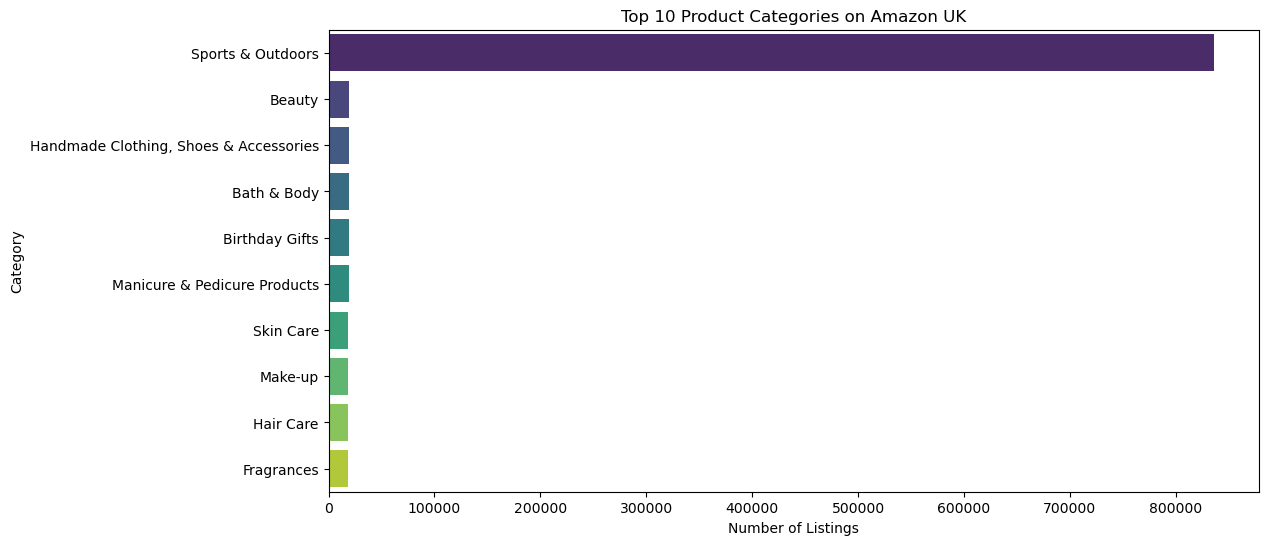

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))
sns.barplot(x=category_counts.head(10).values, y=category_counts.head(10).index, palette="viridis")
plt.title("Top 10 Product Categories on Amazon UK")
plt.xlabel("Number of Listings")
plt.ylabel("Category")
plt.show()


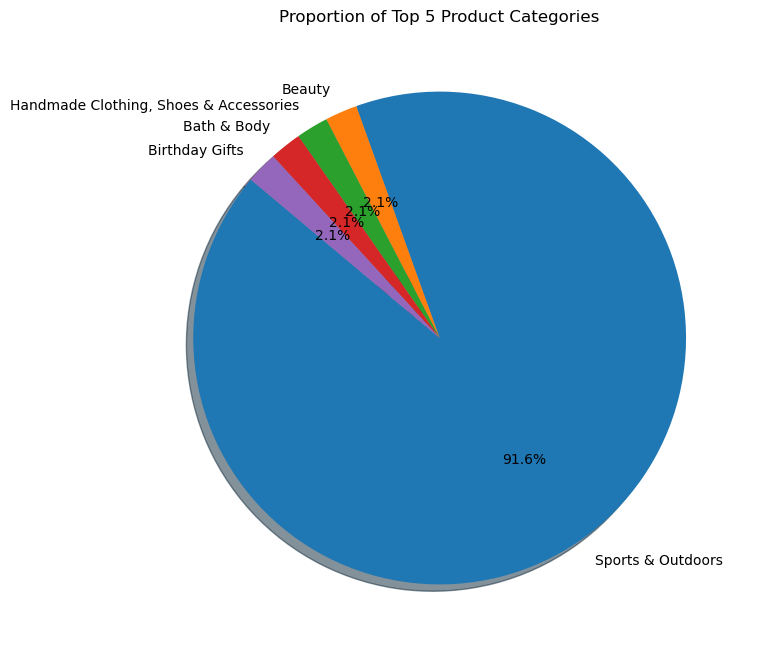

In [12]:
plt.figure(figsize=(8,8))
category_counts.head(5).plot.pie(autopct='%1.1f%%', startangle=140, shadow=True)
plt.title("Proportion of Top 5 Product Categories")
plt.ylabel("")
plt.show()


In [14]:
# Ensure price is numeric
df['price'] = pd.to_numeric(df['price'], errors='coerce')

# Drop missing or zero prices
df = df[df['price'].notnull()]
df = df[df['price'] > 0]

# Preview cleaned prices
df['price'].describe()


count    2.443631e+06
mean     8.924454e+01
std      3.456102e+02
min      1.000000e-02
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [16]:
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode().iloc[0]

print(f"📊 Mean Price: £{mean_price:.2f}")
print(f"📊 Median Price: £{median_price:.2f}")
print(f"📊 Mode Price: £{mode_price:.2f}")


📊 Mean Price: £89.24
📊 Median Price: £19.09
📊 Mode Price: £9.99


In [18]:
price_range = df['price'].max() - df['price'].min()
price_std = df['price'].std()
price_var = df['price'].var()
price_iqr = df['price'].quantile(0.75) - df['price'].quantile(0.25)

print(f"📈 Price Range: £{price_range:.2f}")
print(f"📈 Standard Deviation: £{price_std:.2f}")
print(f"📈 Variance: {price_var:.2f}")
print(f"📈 Interquartile Range (IQR): £{price_iqr:.2f}")


📈 Price Range: £99999.99
📈 Standard Deviation: £345.61
📈 Variance: 119446.40
📈 Interquartile Range (IQR): £36.00


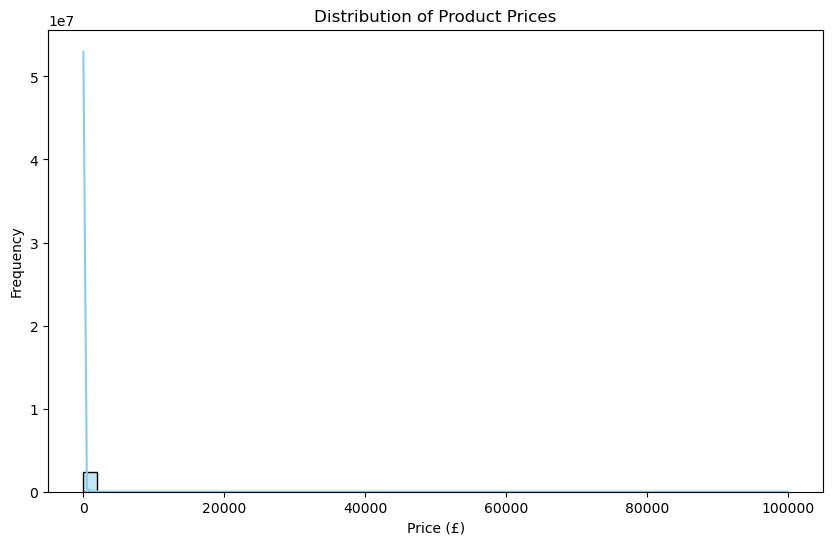

In [21]:
plt.figure(figsize=(10,6))
sns.histplot(df['price'], bins=50, kde=True, color='skyblue')
plt.title("Distribution of Product Prices")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")
plt.show()


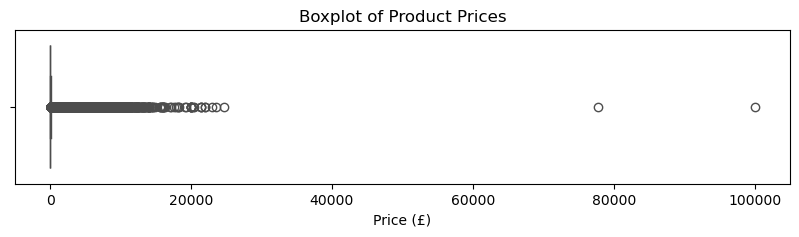

In [23]:
plt.figure(figsize=(10,2))
sns.boxplot(x=df['price'], color='orange')
plt.title("Boxplot of Product Prices")
plt.xlabel("Price (£)")
plt.show()


In [29]:

df.rename(columns={"stars": "rating"}, inplace=True)

# Convert to numeric and drop missing values
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df = df[df['rating'].notnull()]

# Preview cleaned ratings
df['rating'].describe()



count    2.443631e+06
mean     2.152817e+00
std      2.194863e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: rating, dtype: float64

In [31]:
mean_rating = df['rating'].mean()
median_rating = df['rating'].median()
mode_rating = df['rating'].mode().iloc[0]

print(f" Mean Rating: {mean_rating:.2f}")
print(f" Median Rating: {median_rating:.2f}")
print(f" Mode Rating: {mode_rating:.2f}")


 Mean Rating: 2.15
 Median Rating: 0.00
 Mode Rating: 0.00


In [33]:
rating_std = df['rating'].std()
rating_var = df['rating'].var()
rating_iqr = df['rating'].quantile(0.75) - df['rating'].quantile(0.25)

print(f" Standard Deviation: {rating_std:.2f}")
print(f" Variance: {rating_var:.2f}")
print(f" Interquartile Range (IQR): {rating_iqr:.2f}")


 Standard Deviation: 2.19
 Variance: 4.82
 Interquartile Range (IQR): 4.40


In [35]:
from scipy.stats import skew, kurtosis

rating_skew = skew(df['rating'])
rating_kurt = kurtosis(df['rating'])

print(f" Skewness: {rating_skew:.2f}")
print(f" Kurtosis: {rating_kurt:.2f}")


 Skewness: 0.08
 Kurtosis: -1.93


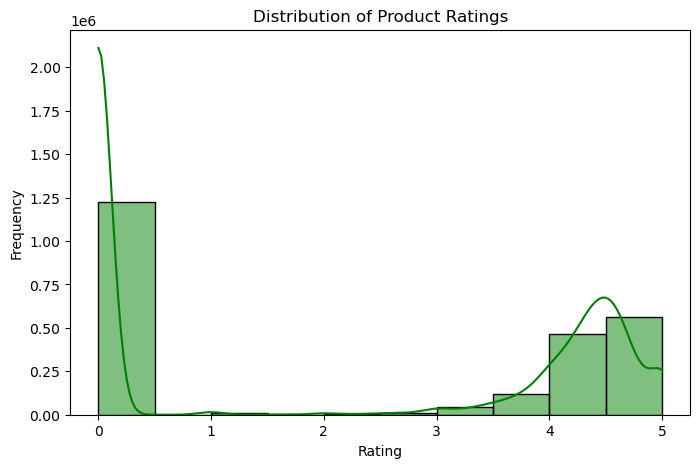

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(df['rating'], bins=10, kde=True, color='green')
plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()
